# Weight initialization: why `std = gain / √fan_in`

**The question:** are we trying to make the *weights* Gaussian, or the *weighted sum* Gaussian?

**Short answer:** neither is the real goal. We want the **activations to keep a stable spread (std ≈ 1) from layer to layer**. Gaussian weights are just a convenient way to generate random numbers with the std we choose.

**Notebook map**
1. Setup (imports, data)
2. Refresher: standard deviation
3. The logic chain, step by step, with a small experiment for each step
4. Applying the rule to the real MLP
5. Training, evaluation, sampling

## 1. Setup

In [17]:
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
from torch.nn.functional import cross_entropy
%matplotlib inline

words = open('../names.txt', 'r').read().splitlines()  # 32033
chars = sorted(list(set(''.join(words))))
stoi = {s: i + 1 for i, s in enumerate(chars)}
stoi['.'] = 0
itos = {i: s for s, i in stoi.items()}
vocab_size = len(itos)
print(itos)
print(vocab_size)

{1: 'a', 2: 'b', 3: 'c', 4: 'd', 5: 'e', 6: 'f', 7: 'g', 8: 'h', 9: 'i', 10: 'j', 11: 'k', 12: 'l', 13: 'm', 14: 'n', 15: 'o', 16: 'p', 17: 'q', 18: 'r', 19: 's', 20: 't', 21: 'u', 22: 'v', 23: 'w', 24: 'x', 25: 'y', 26: 'z', 0: '.'}
27


In [18]:
block_size = 3


def build_dateset(words):
    X, Y = [], []

    for w in words:
        # fill 3 letters in x fill next in y
        context = [0] * block_size
        for ch in w + '.':
            ix = stoi[ch]
            X.append(context)  # 0.0.0 on first iteration
            Y.append(ix)
            context = context[1:] + [ix]
    X = torch.tensor(X)
    Y = torch.tensor(Y)
    print(X.shape, Y.shape)
    return X, Y


import random

# first we want to shuffle the words
# then we want 80% training set
# then we want 10% dev test
# then we want 10% final test

random.seed(42)
random.shuffle(words)
n1 = int(0.8 * len(words))
n2 = int(0.9 * len(words))

train_data = words[:n1]
dev_data = words[n1:n2]
test_data = words[n2:]

Xtr, Ytr = build_dateset(train_data)
Xdev, Ydev = build_dateset(dev_data)
Xtest, Ytest = build_dateset(test_data)

torch.Size([182625, 3]) torch.Size([182625])
torch.Size([22655, 3]) torch.Size([22655])
torch.Size([22866, 3]) torch.Size([22866])


## 2. Refresher: standard deviation

"Size" of a bunch of numbers = how far they typically are from zero (ignoring the sign). The precise measure is the **standard deviation (std)**. == Стандартно отклонение (standard deviation) показва колко са разпръснати стойностите около средната стойност.

## Formulas

Population:  σ = √( Σ(xᵢ − μ)² / N )

Sample:      s = √( Σ(xᵢ − x̄)² / (n − 1) )

Where:
- xᵢ = each value
- μ or x̄ = the mean
- N or n = number of values
- Σ = sum over all values

## Example

Data: 2, 4, 4, 4, 5, 5, 7, 9

1. Mean: (2 + 4 + 4 + 4 + 5 + 5 + 7 + 9) / 8 = 40 / 8 = 5
2. Squared differences from the mean: 9, 1, 1, 1, 0, 0, 4, 16 → sum = 32
3. Variance: population 32 / 8 = 4, sample 32 / 7 ≈ 4.57
4. Square root: population SD = √4 = 2, sample SD = √4.57 ≈ 2.14

You can read "std = 1" as *"numbers typically around 1 away from zero"*.

`torch.randn` gives numbers with std = 1, so **multiplying by a number sets the new std** to that number:

In [19]:
# torch.randn -> makes std 1 -> so whatever the multiplier is, that is the new standard deviation
(torch.randn(100000) * 0.3).std()

tensor(0.3004)

In [20]:
# the bigger the sample - the closer the std is to 1
torch.randn(100000000).std()

tensor(1.0001)

## 3. The logic chain

### Step 1: what a neuron computes
A neuron multiplies each input by a weight and adds everything up (plus a bias, which we set to ~0 here).
Each product `w·x` is a **term**. The total is the **sum**, called the **pre-activation**.

Tiny example with 3 inputs:
- inputs `x = 0.5, -1.2, 0.8`, weights `w = 0.3, -0.7, 1.1`
- terms: `0.15, 0.84, 0.88` → sum = `1.87`
- same inputs but weights 10x smaller (`0.03, -0.07, 0.11`) → terms `0.015, 0.084, 0.088` → sum = `0.187`

**The size of the weights decides the size of the terms, which decides the size of the sum.** We get to choose the weight size at initialization.

### Step 2: the coin fact
When you add many random numbers (some positive, some negative), they partly cancel, but the total still drifts away from zero.
The typical distance grows like **√(how many you add)**, not like how many you add.

In [44]:
# Coin game: each coin is +1 or -1. Add n of them, repeat 10000 times, look at the typical size of the total.
for n in [1, 4, 100, 10000]:
    coins = torch.randint(0, 2, (10000, n)) * 2 - 1   # random +1 / -1
    totals = coins.sum(dim=1).float()
    print("totals shape:", totals.shape)
    print(f"{n:6d} coins -> typical size of total (std): {totals.std():7.2f}   sqrt(n) = {n**0.5:.2f}")
    print(totals[:6])
    totals /= n**0.5
    print(totals[:6])
    print(f"{n:6d} coins -> typical size of total (std): {totals.std():7.2f}   sqrt(n) = {n**0.5:.2f}\n")

totals shape: torch.Size([10000])
     1 coins -> typical size of total (std):    1.00   sqrt(n) = 1.00
tensor([ 1., -1., -1., -1.,  1., -1.])
tensor([ 1., -1., -1., -1.,  1., -1.])
     1 coins -> typical size of total (std):    1.00   sqrt(n) = 1.00

totals shape: torch.Size([10000])
     4 coins -> typical size of total (std):    1.99   sqrt(n) = 2.00
tensor([2., 0., 2., 4., 2., 0.])
tensor([1., 0., 1., 2., 1., 0.])
     4 coins -> typical size of total (std):    1.00   sqrt(n) = 2.00

totals shape: torch.Size([10000])
   100 coins -> typical size of total (std):   10.01   sqrt(n) = 10.00
tensor([ 10.,  -2.,  12., -10.,   0.,  -2.])
tensor([ 1.0000, -0.2000,  1.2000, -1.0000,  0.0000, -0.2000])
   100 coins -> typical size of total (std):    1.00   sqrt(n) = 10.00

totals shape: torch.Size([10000])
 10000 coins -> typical size of total (std):  100.26   sqrt(n) = 100.00
tensor([-206.,   92.,  -62.,  130.,  -24., -160.])
tensor([-2.0600,  0.9200, -0.6200,  1.3000, -0.2400, -1.6000])
 

In [22]:
# Same thing with gaussian numbers (std 1): adding n of them gives std ~ sqrt(n)
for n in [1, 4, 100, 10000]:
    totals = torch.randn(10000, n).sum(dim=1)
    print(f"{n:6d} terms -> std of sum: {totals.std():7.2f}   sqrt(n) = {n**0.5:.2f}")

     1 terms -> std of sum:    1.00   sqrt(n) = 1.00
     4 terms -> std of sum:    2.00   sqrt(n) = 2.00
   100 terms -> std of sum:    9.97   sqrt(n) = 10.00
 10000 terms -> std of sum:  100.58   sqrt(n) = 100.00


### Step 3: the problem, growth
A neuron with `fan_in = 100` adds 100 terms. If inputs and weights both have std ≈ 1, each term has size ~1, so the **sum has std ≈ 10**.
The next layer then receives inputs of size 10, produces sums of size ~100, and so on.
The numbers explode, tanh saturates at ±1, and gradients die.

Below: `x` has std 1, `w` has std 1, `fan_in = 10`. Look at `y.std()`: it is about √10 ≈ 3.16, not 1.

x mean: tensor(0.0057)  x std: tensor(1.0026)
y mean: tensor(-0.0048)  y std: tensor(3.2034)


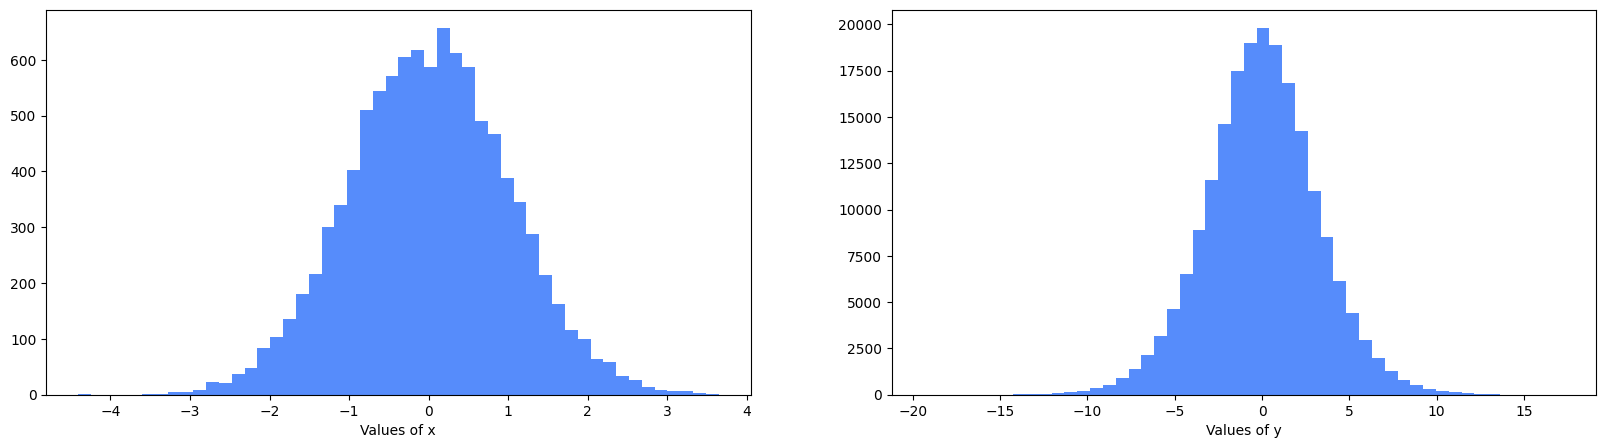

In [23]:
x = torch.randn(1000, 10)
w = torch.randn(10, 200)          # std 1, no correction
y = x @ w

print("x mean:", x.mean(), " x std:", x.std())
print("y mean:", y.mean(), " y std:", y.std())   # ~ sqrt(10) = 3.16, the sum is much wider than the input

plt.figure(figsize=(20, 5))

plt.subplot(121)
plt.hist(x.view(-1).tolist(), 50)  # density is not probability!!!!!!!!
plt.xlabel("Values of x")

plt.subplot(122)
plt.hist(y.view(-1).tolist(), 50)
plt.xlabel("Values of y")
plt.show()

### Step 4: fix #1, divide the weights by √fan_in
`fan_in` = the number of inputs going into **one** neuron (not the total number of weights in the network).
If the weights have std `1/√fan_in`, each term shrinks by that factor, and adding `fan_in` terms grows the total by `√fan_in`. The two cancel, so **input std ≈ 1 gives sum std ≈ 1**.

Note: we divide by the **square root** of fan_in. Dividing by fan_in itself would make the sum far too small.

Same experiment, now with `/ fan_in**0.5`. `y.std()` ≈ 1:

x mean: tensor(0.0169)  x std: tensor(0.9998)
y mean: tensor(0.0019)  y std: tensor(1.0040)


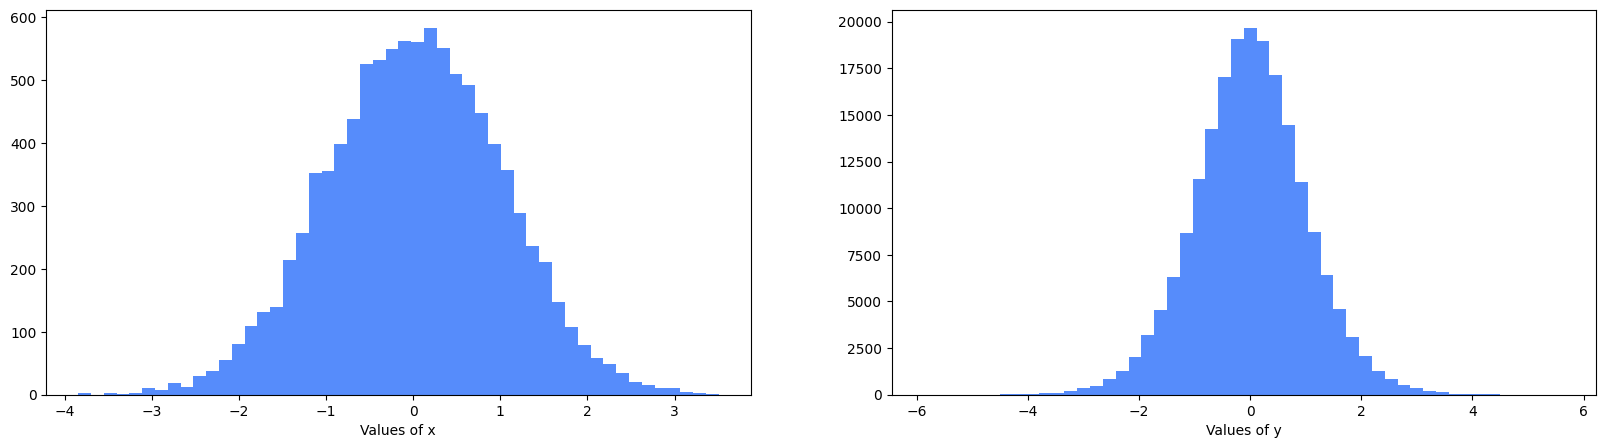

In [24]:
x = torch.randn(1000, 10)
w = torch.randn(10, 200) / 10**0.5   # / sqrt of fan_in (the number of inputs)
y = x @ w

print("x mean:", x.mean(), " x std:", x.std())
print("y mean:", y.mean(), " y std:", y.std())   # ~ 1

plt.figure(figsize=(20, 5))

plt.subplot(121)
plt.hist(x.view(-1).tolist(), 50)
plt.xlabel("Values of x")

plt.subplot(122)
plt.hist(y.view(-1).tolist(), 50)
plt.xlabel("Values of y")
plt.show()

### Step 5: the second problem, shrinking
After the sum, the activation function is applied. tanh **squashes** values toward ±1, so its output has a smaller spread than its input.
Input std ≈ 1 comes out with std ≈ 0.63. Layer after layer: 1 → 0.63 → 0.4 → 0.25 → ... the activations fade toward 0.

In [25]:
pre = torch.randn(100000)          # pre-activations with std 1
print("tanh input  std:", pre.std().item())
print("tanh output std:", torch.tanh(pre).std().item())   # ~ 0.63

tanh input  std: 1.0022228956222534
tanh output std: 0.6286277174949646


### Step 6: fix #2, gain
**Gain** is an extra multiplier on the weights. Slightly bigger weights give a slightly bigger sum (std a bit **above** 1 on purpose), so after tanh squashes it, the activations no longer fade away. In a deep stack they settle at a stable std (around 0.65 for gain 5/3), instead of shrinking toward 0.

Each activation squashes differently, so each gets its own gain (see the PyTorch table: https://docs.pytorch.org/docs/2.14/nn.init.html):

| activation | gain |
|---|---|
| linear (no activation) | 1 |
| tanh | 5/3 ≈ 1.67  (0.63 × 1.67 ≈ 1) |
| ReLU | √2 (it zeroes out half the values) |

Caveat: 5/3 is an empirical average recommended for tanh, not an exact value. In practice activations stay roughly stable, not perfectly at 1. The run below shows it: gain 1 fades, gain 5/3 holds steady, gain 3 holds steady too but pushes tanh toward saturation.

In [26]:
# Push data through 10 tanh layers and watch the std of the activations
def run_layers(gain, n_layers=10, fan_in=100):
    a = torch.randn(1000, fan_in)
    stds = []
    for _ in range(n_layers):
        W = torch.randn(fan_in, fan_in) * gain / fan_in**0.5
        a = torch.tanh(a @ W)
        stds.append(round(a.std().item(), 3))
    return stds

print("gain = 1   :", run_layers(1))       # keeps fading toward 0
print("gain = 5/3 :", run_layers(5/3))     # settles at a stable value, no fading
print("gain = 3   :", run_layers(3))       # stable but too big -> tanh pushed toward +-1

gain = 1   : [0.625, 0.491, 0.414, 0.357, 0.32, 0.291, 0.271, 0.248, 0.242, 0.235]
gain = 5/3 : [0.759, 0.694, 0.667, 0.663, 0.655, 0.649, 0.644, 0.644, 0.654, 0.65]
gain = 3   : [0.862, 0.842, 0.839, 0.838, 0.84, 0.837, 0.84, 0.84, 0.838, 0.841]


### Step 7: the final rule

`std of weights = gain / √fan_in`

- `1/√fan_in` cancels the **growth** from adding many terms.
- `gain` cancels the **shrinking** from the activation function.

### Step 8: one neuron vs. many
We derive the rule for one neuron, then apply it to all of them. Every neuron in a layer has the same `fan_in`, so one line builds the whole layer:

`W = torch.randn(fan_in, fan_out) * gain / fan_in**0.5`

Each **column** of `W` is one neuron. "Std ≈ 1" describes the spread across many neurons and many examples together, not one specific number.

### Step 9: the original question, answered
We are not trying to make the weights Gaussian for its own sake. The real goal is to keep the std of the **activations** (the values passed to the next layer) roughly constant from layer to layer, neither exploding nor fading. Gaussian weights are just a convenient way to produce random numbers with the std we want.

## 4. Applying the rule to the real MLP

In the previous notebook we placed `0.2` as the multiplier for `W1` by hand. In big nets nobody does that, so we use `gain / √fan_in`.
Here `fan_in = n_embd * block_size = 30` and `gain = 5/3` (tanh).

`W2` and `b1`, `b2` are left as before (small output weights so the initial logits are small, biases zero).

**Background reading**
- Kaiming init paper (ReLU: weights gaussian with std √(2/fan_in)): https://arxiv.org/abs/1502.01852
- Batch norm paper: https://arxiv.org/abs/1502.03167
- PyTorch init docs: https://docs.pytorch.org/docs/2.14/nn.init.html

The paper's key point: if the initialization is right, the forward pass behaves well **and** the backward pass behaves well too.
We want the pre-activations to be neither too big (tanh saturates) nor too close to zero (tanh(x) ≈ x, so no nonlinearity).

In [27]:
# MLP revisited
n_embd = 10  # the dimensionality of the character embedding vectors
n_hidden = 200

g = torch.Generator().manual_seed(2147483647)
C = torch.randn((vocab_size, n_embd),             generator=g)      # torch.Size([27, 10])
# W1 = torch.randn((n_embd * block_size, n_hidden), generator=g) * 0.2    # old way: manual multiplier
# proper way to set
W1 = torch.randn((n_embd * block_size, n_hidden), generator=g) * (5/3)/((n_embd*block_size)**0.5)  # torch.Size([30,200])
b1 = torch.randn(n_hidden,                        generator=g) * 0      # torch.Size([200])
W2 = torch.randn((n_hidden, vocab_size),          generator=g) * 0.1  # torch.Size([200,27])
b2 = torch.randn(vocab_size,                      generator=g) * 0    # torch.Size([27,])

parameters = [C, W1, b1, W2, b2]

print(sum(p.nelement() for p in parameters))  # 11897
for p in parameters:
    p.requires_grad = True

11897


## 5. Training, evaluation, sampling

In [28]:
max_steps = 200_000
batch_size = 32
lossi = []

for i in range(200_000):

    ix = torch.randint(0, Xtr.shape[0], (batch_size,), generator=g)
    Xb, Yb = Xtr[ix], Ytr[ix]  # batch X, Y

    #forward pass
    emb = C[Xb]  # 32 samples of context of 3 letters each embedded in 10 numbers
    embcat = emb.view(emb.shape[0], -1)  # concatenate the vectors
    hpreact = embcat @ W1 + b1
    h = torch.tanh(hpreact)
    logits = h @ W2 + b2
    loss = F.cross_entropy(logits, Yb)

    #backward pass
    for p in parameters:
        p.grad = None
    loss.backward()

    lr = 0.01 if i < 100_000 else 0.001
    for p in parameters:
        p.data += - lr * p.grad

    if i % 10_000 == 0:
        print(f'{i:7d} /{max_steps:7d}: {loss.item():.4f}')
    lossi.append(loss.log10().item())
    break;  # NOTE: stops after 1 step (quick test). Delete this line to train for all 200k steps.

      0 / 200000: 3.9518


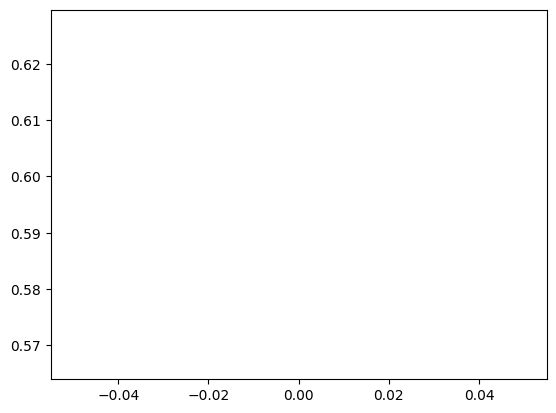

In [29]:
plt.plot(lossi)

In [30]:
@torch.no_grad() # this decorator disables gradient tracking
def split_loss(split):
    # x, y = {'train': (Xtr, Ytr),
    #         'val': (Xdev, Ydev),
    #         'test': (Xtest, Ytest),
    #         }[split]

    if split == 'train':
        x, y = Xtr, Ytr
    elif split == 'val':
        x, y = Xdev, Ydev
    elif split == 'test':
        x, y = Xtest, Ytest

    emb = C[x] # (total entries, block_size, n_embd)
    embcat = emb.view(emb.shape[0],-1) # concat into (N, block_size * n_embd)
    h = torch.tanh(embcat @ W1 + b1) # (N, n_hidden)
    logits = h @ W2 + b2 # (N, vocab_size)
    loss = F.cross_entropy(logits, y)
    print(split, loss.item())

split_loss('train')
split_loss('val')

train 3.827756404876709
val 3.825104236602783


In [31]:
g = torch.Generator().manual_seed(2147483647+10)

for _ in range(20):
    out = []
    context = [0]*block_size #initialize with all ...

    while True:
        emb = C[torch.tensor([context])] # (1,block_size, n_embd)
        h = torch.tanh(emb.view(1,-1)@ W1 + b1 )
        logits = h @ W2 + b2
        probs = F.softmax(logits, dim=1)
        # sample from the distribution
        ix = torch.multinomial(probs, num_samples=1, generator=g).item()
        # shift the context window and track the samples
        context = context[1:]+[ix]
        out.append(ix)
        # if we sample the special '.' token, break
        if ix == 0:
            break

    print(''.join(itos[i] for i in out)) # decode and print the generated word

cbrpzvfqhoflqruhcjmrzxvthgjkhgcjysgejrrhuhjfbgksrrwpvgqhicoesmuipjcmmiirduxjeggpdzsmgpows.
qbgjtis.
ouxwaljiqbq.
wqxtlojdiaryxixfkcgkpigslxjef.
gpoip.
gtlsfwysfwyoapaemoukjrksyadimqqosozswplojn.
cokhifryodkpfzadlduodnoebsrksrauhrynhgaopllmtnraes.
xqholoqnpsbvbwdeyipvqmuitjgbvzmhpodgpycsvslqhkkrnu.
zfkkrynadfkhkbp.
skcthmzimdtevl.
ky.
q.
cctfouowoyttbjjohczftjcj.
zolndzse.
ku.
eoaigtkxerrqci.
kcfkyrbadiieluguyozwyysdyokhmlkfkkromcaddtxhvkoyndiwuwpxksxwymszxqpotzsik.
z.
rngpknbflntixsfwdkkjhfj.
kugkrvzhpvwbepodvkhhkxrnmttoscvnpgewjmjqfwjthgfwkewjdfxckxdytzvhgkpmytzl.
